# Brasil em Dados

## Redução de dimensionalidade — PCA

Este notebook aplica a Análise de Componentes Principais (PCA) aos
indicadores socioeconômicos e educacionais dos municípios.

O PCA busca representar as variáveis originais em um número menor de
componentes, preservando uma parte importante da variabilidade dos dados.

O IDEB não será usado para calcular os componentes, pois é um indicador
construído a partir de medidas de desempenho e rendimento. Depois do PCA,
os componentes poderão ser comparados ao IDEB para fins exploratórios.

## 1. Configuração e carregamento da base

Será utilizada a base integrada gerada no primeiro notebook. Para o PCA,
serão mantidos apenas os municípios completos nas variáveis selecionadas.
Como o IDEB não entra no cálculo, sua ausência não será motivo para excluir
um município desta etapa.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from IPython.display import display

PROJECT_ROOT = Path("..")

DATA_PROCESSED = PROJECT_ROOT / "data" / "processed"
FIGURES = PROJECT_ROOT / "figures"

DATA_PROCESSED.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

arquivo_base_integrada = (
    DATA_PROCESSED / "brasil_em_dados_municipios.csv"
)

df_integrado = pd.read_csv(
    arquivo_base_integrada,
    encoding="utf-8-sig",
    dtype={"codigo_municipio": "Int64"}
)

print("Dimensões da base integrada:", df_integrado.shape)
display(df_integrado.head())

Dimensões da base integrada: (5569, 13)


,uf,codigo_municipio,municipio,REDE,taxa_aprovacao_2023,indicador_rendimento_2023,nota_matematica_2023,nota_portugues_2023,nota_media_2023,ideb_2023,populacao_2022,renda_domiciliar_per_capita_2022,observacao
0,RO,1100015,Alta Floresta D'Oeste,Pública,93.2,0.931733,254.11,246.21,5.005333,4.7,21494.0,1210.60,NaN
1,RO,1100023,Ariquemes,Pública,93.8,0.937832,251.95,251.99,5.065667,4.8,96833.0,1458.57,NaN
2,RO,1100031,Cabixi,Pública,99.7,0.997227,247.93,252.78,5.011833,5.0,5351.0,1323.79,NaN
3,RO,1100049,Cacoal,Pública,98.8,0.988228,247.61,249.67,4.954667,4.9,86887.0,1625.88,NaN
4,RO,1100056,Cerejeiras,Pública,96.7,0.966651,255.25,252.94,5.136500,5.0,15890.0,1554.33,NaN


## 2. Seleção das variáveis para o PCA

Serão utilizadas cinco variáveis: logaritmo da população, renda per
capita, taxa de aprovação e notas de Matemática e Português.

O IDEB será excluído do cálculo para evitar incluí-lo junto com medidas
que participam da sua construção. As variáveis serão padronizadas antes
do PCA porque possuem unidades e escalas diferentes.

In [2]:
variaveis_pca = [
    "log_populacao_2022",
    "renda_domiciliar_per_capita_2022",
    "taxa_aprovacao_2023",
    "nota_matematica_2023",
    "nota_portugues_2023"
]

colunas_identificacao = [
    "uf",
    "codigo_municipio",
    "municipio"
]

variaveis_originais = [
    "populacao_2022",
    "renda_domiciliar_per_capita_2022",
    "taxa_aprovacao_2023",
    "nota_matematica_2023",
    "nota_portugues_2023"
]

df_pca = df_integrado[
    colunas_identificacao + variaveis_originais
].copy()

for coluna in variaveis_originais:
    df_pca[coluna] = pd.to_numeric(
        df_pca[coluna],
        errors="coerce"
    )

df_pca = df_pca.dropna(
    subset=variaveis_originais
).copy()

df_pca["log_populacao_2022"] = np.log1p(
    df_pca["populacao_2022"]
)

print("Municípios na base integrada:", len(df_integrado))
print("Municípios utilizados no PCA:", len(df_pca))
print(
    "Municípios excluídos por valores ausentes nas variáveis do PCA:",
    len(df_integrado) - len(df_pca)
)

display(df_pca[variaveis_pca].head())

Municípios na base integrada: 5569
Municípios utilizados no PCA: 5382
Municípios excluídos por valores ausentes nas variáveis do PCA: 187


,log_populacao_2022,renda_domiciliar_per_capita_2022,taxa_aprovacao_2023,nota_matematica_2023,nota_portugues_2023
0,9.975576,1210.60,93.2,254.11,246.21
1,11.480753,1458.57,93.8,251.95,251.99
2,8.585226,1323.79,99.7,247.93,252.78
3,11.372375,1625.88,98.8,247.61,249.67
4,9.673508,1554.33,96.7,255.25,252.94


## 3. Padronização das variáveis

O PCA é sensível à escala das variáveis. Por isso, será aplicado o
`StandardScaler`, que transforma cada variável para ter média próxima de
zero e desvio-padrão próximo de um.

Nesta análise exploratória, o PCA será ajustado sobre toda a base
selecionada. Se os componentes forem usados posteriormente em um modelo
preditivo, o padronizador e o PCA deverão ser ajustados apenas com os
dados de treino.

In [3]:
X = df_pca[variaveis_pca].copy()

padronizador = StandardScaler()
X_padronizado = padronizador.fit_transform(X)

print("Médias após padronização:")
print(np.round(X_padronizado.mean(axis=0), 4))

print("\nDesvios-padrão após padronização:")
print(np.round(X_padronizado.std(axis=0), 4))

Médias após padronização:
[-0.  0. -0. -0.  0.]

Desvios-padrão após padronização:
[1. 1. 1. 1. 1.]


## 4. Aplicação do PCA e variância explicada

O PCA será calculado para todas as variáveis selecionadas. Em seguida,
será examinada a variância explicada por cada componente e sua soma
acumulada.

O limite de 80% será usado como referência exploratória, não como regra
automática: a decisão sobre quantos componentes manter também deve
considerar a interpretabilidade dos resultados.

In [4]:
pca = PCA()
scores_pca = pca.fit_transform(X_padronizado)

variancia_explicada = pca.explained_variance_ratio_
variancia_acumulada = np.cumsum(variancia_explicada)

tabela_variancia = pd.DataFrame({
    "componente": [
        f"CP{i}"
        for i in range(1, len(variaveis_pca) + 1)
    ],
    "variancia_explicada": variancia_explicada,
    "variancia_acumulada": variancia_acumulada
})

display(
    tabela_variancia.style.format({
        "variancia_explicada": "{:.2%}",
        "variancia_acumulada": "{:.2%}"
    })
)

numero_componentes_80 = (
    np.argmax(variancia_acumulada >= 0.80) + 1
)

numero_componentes_90 = (
    np.argmax(variancia_acumulada >= 0.90) + 1
)

print(
    "Componentes necessários para explicar pelo menos 80%:",
    numero_componentes_80
)

print(
    "Componentes necessários para explicar pelo menos 90%:",
    numero_componentes_90
)

,componente,variancia_explicada,variancia_acumulada
0,CP1,49.58%,49.58%
1,CP2,21.40%,70.98%
2,CP3,15.17%,86.15%
3,CP4,12.28%,98.43%
4,CP5,1.57%,100.00%


Componentes necessários para explicar pelo menos 80%: 3
Componentes necessários para explicar pelo menos 90%: 4


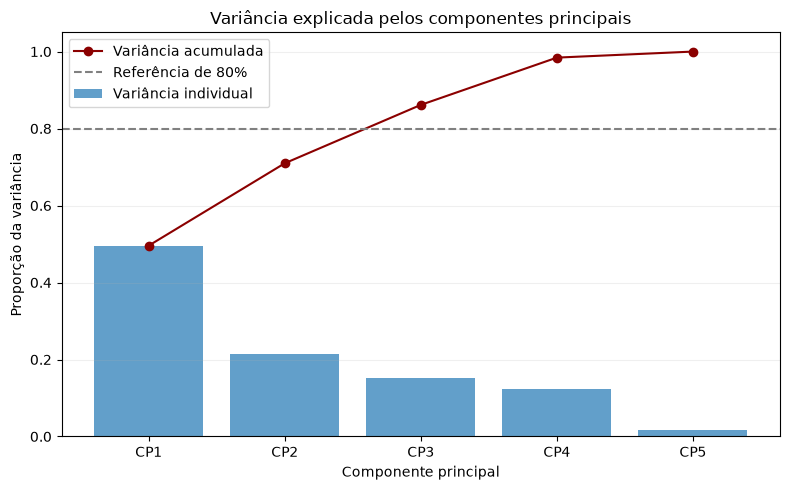

In [5]:
posicoes = np.arange(1, len(variancia_explicada) + 1)

plt.figure(figsize=(8, 5))

plt.bar(
    posicoes,
    variancia_explicada,
    alpha=0.7,
    label="Variância individual"
)

plt.plot(
    posicoes,
    variancia_acumulada,
    marker="o",
    color="darkred",
    label="Variância acumulada"
)

plt.axhline(
    0.80,
    color="gray",
    linestyle="--",
    label="Referência de 80%"
)

plt.xticks(
    posicoes,
    [f"CP{i}" for i in posicoes]
)

plt.xlabel("Componente principal")
plt.ylabel("Proporção da variância")
plt.title("Variância explicada pelos componentes principais")
plt.ylim(0, 1.05)
plt.grid(axis="y", alpha=0.2)
plt.legend()
plt.tight_layout()
plt.show()

## 5. Pesos e cargas dos componentes

Os coeficientes dos componentes mostram como as variáveis originais
participam da construção de cada componente. Como alternativa de
interpretação, também serão calculadas as cargas, que representam a
associação entre cada variável padronizada e cada componente.

O sinal dos componentes pode inverter sem alterar a solução matemática.
Por isso, a interpretação deve considerar principalmente o padrão e a
magnitude dos valores, e não o sinal isoladamente.

In [6]:
nomes_variaveis_pca = {
    "log_populacao_2022": "Log da população",
    "renda_domiciliar_per_capita_2022": "Renda per capita",
    "taxa_aprovacao_2023": "Aprovação",
    "nota_matematica_2023": "Matemática",
    "nota_portugues_2023": "Português"
}

nomes_linhas = [
    nomes_variaveis_pca[coluna]
    for coluna in variaveis_pca
]

nomes_componentes = [
    f"CP{i}"
    for i in range(1, len(variaveis_pca) + 1)
]

coeficientes_pca = pd.DataFrame(
    pca.components_.T,
    index=nomes_linhas,
    columns=nomes_componentes
)

cargas_pca = pd.DataFrame(
    pca.components_.T
    * np.sqrt(pca.explained_variance_),
    index=nomes_linhas,
    columns=nomes_componentes
)

print("Coeficientes dos componentes:")
display(coeficientes_pca.round(3))

print("Cargas das variáveis nos componentes:")
display(cargas_pca.round(3))

Coeficientes dos componentes:


,CP1,CP2,CP3,CP4,CP5
Log da população,-0.020,0.904,0.317,-0.280,-0.059
Renda per capita,0.422,0.327,-0.178,0.826,-0.016
Aprovação,0.359,-0.267,0.887,0.114,0.011
Matemática,0.588,-0.064,-0.205,-0.333,-0.705
Português,0.589,0.023,-0.197,-0.339,0.706


Cargas das variáveis nos componentes:


,CP1,CP2,CP3,CP4,CP5
Log da população,-0.032,0.935,0.276,-0.220,-0.017
Renda per capita,0.665,0.338,-0.155,0.648,-0.004
Aprovação,0.565,-0.276,0.773,0.089,0.003
Matemática,0.926,-0.066,-0.179,-0.261,-0.197
Português,0.928,0.024,-0.171,-0.266,0.198


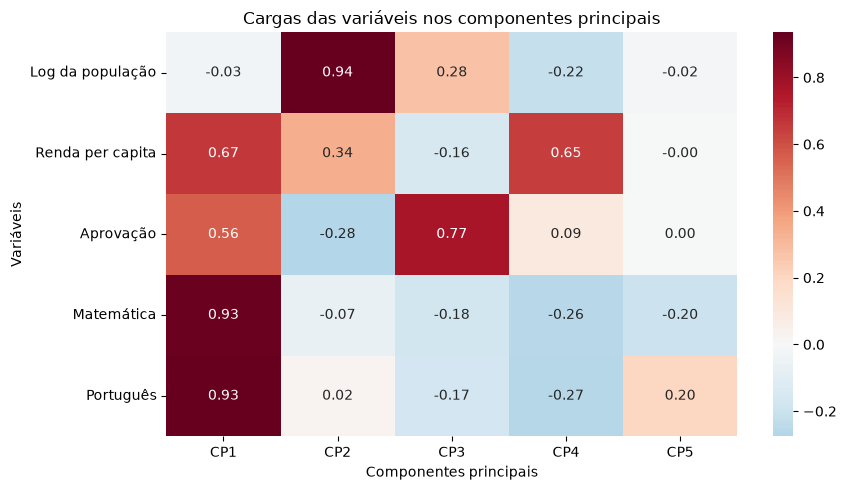

In [7]:
plt.figure(figsize=(9, 5))

sns.heatmap(
    cargas_pca,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0
)

plt.title("Cargas das variáveis nos componentes principais")
plt.xlabel("Componentes principais")
plt.ylabel("Variáveis")
plt.tight_layout()
plt.show()

## 6. Visualização dos municípios nos componentes

O gráfico a seguir posiciona cada município de acordo com seus dois
primeiros componentes. A cor representa a faixa de renda, para facilitar
a observação de possíveis agrupamentos.

A projeção em duas dimensões não mostra toda a informação se mais de
dois componentes forem necessários para representar adequadamente os
dados.

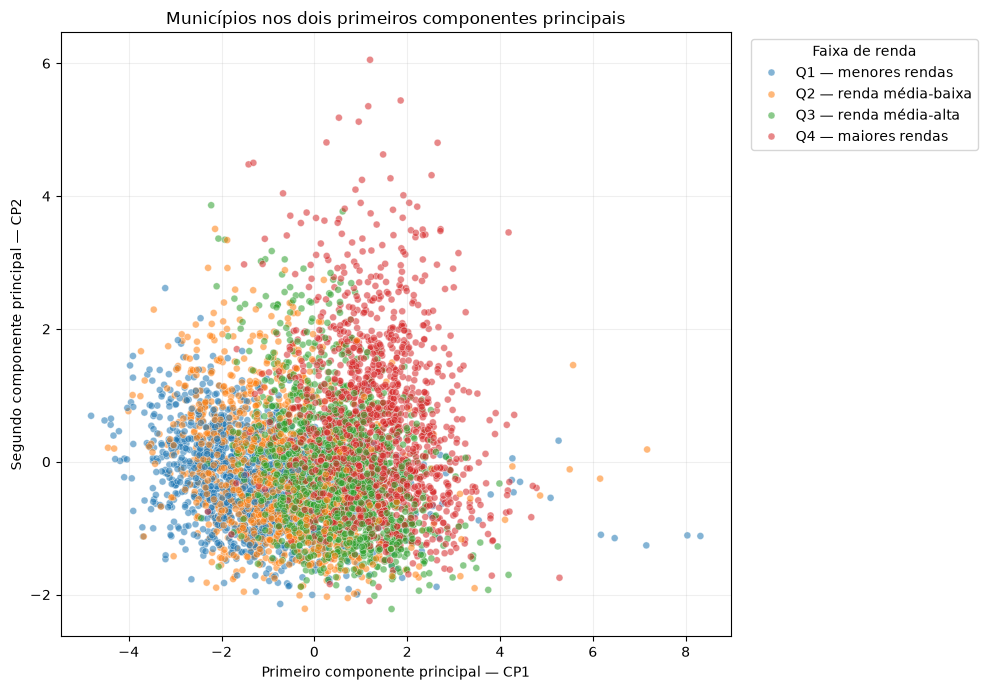

In [8]:
df_scores = df_pca[colunas_identificacao].reset_index(drop=True).copy()

for i in range(scores_pca.shape[1]):
    df_scores[f"CP{i + 1}"] = scores_pca[:, i]

df_scores["faixa_renda"] = pd.qcut(
    df_pca["renda_domiciliar_per_capita_2022"].reset_index(drop=True),
    q=4,
    labels=[
        "Q1 — menores rendas",
        "Q2 — renda média-baixa",
        "Q3 — renda média-alta",
        "Q4 — maiores rendas"
    ]
)

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=df_scores,
    x="CP1",
    y="CP2",
    hue="faixa_renda",
    alpha=0.55,
    s=25
)

plt.xlabel("Primeiro componente principal — CP1")
plt.ylabel("Segundo componente principal — CP2")
plt.title("Municípios nos dois primeiros componentes principais")
plt.grid(alpha=0.2)
plt.legend(
    title="Faixa de renda",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.tight_layout()
plt.show()

## 7. Comparação exploratória dos componentes com o IDEB

O IDEB não participou do cálculo dos componentes. Nesta etapa, será
comparado com os escores do PCA apenas para investigar se os componentes
apresentam associação com o resultado educacional.

Essa comparação é exploratória e não deve ser interpretada como
evidência de causalidade nem como avaliação de desempenho preditivo.

In [9]:
df_ideb = df_integrado[
    ["codigo_municipio", "ideb_2023"]
].copy()

df_ideb["ideb_2023"] = pd.to_numeric(
    df_ideb["ideb_2023"],
    errors="coerce"
)

df_scores_com_ideb = df_scores.merge(
    df_ideb,
    on="codigo_municipio",
    how="left",
    validate="one_to_one"
)

colunas_componentes = [
    coluna
    for coluna in df_scores_com_ideb.columns
    if coluna.startswith("CP")
]

correlacoes_componentes_ideb = (
    df_scores_com_ideb[colunas_componentes + ["ideb_2023"]]
    .corr(method="spearman")["ideb_2023"]
    .drop("ideb_2023")
    .to_frame("correlacao_spearman_com_ideb")
)

display(correlacoes_componentes_ideb.round(3))

,correlacao_spearman_com_ideb
CP1,0.947
CP2,-0.150
CP3,0.142
CP4,-0.074
CP5,0.041


## 8. Síntese da redução de dimensionalidade

A Análise de Componentes Principais (PCA) foi realizada com cinco variáveis padronizadas: logaritmo da população, rendimento domiciliar per capita, taxa de aprovação e notas de Matemática e Português. Após a remoção dos registros com dados ausentes nessas variáveis, foram analisados 5.382 municípios.

A primeira componente principal (CP1) explicou 49,58% da variância e apresentou maior contribuição das notas de Matemática e Português, além de contribuições do rendimento e da taxa de aprovação. A segunda componente (CP2) explicou 21,40% e foi associada principalmente ao logaritmo da população. Juntas, as duas primeiras componentes explicaram 70,98% da variância total.

Considerando três componentes, a variância explicada acumulada foi de 86,15%; com quatro, chegou a 98,43%. Assim, três componentes podem ser usadas para uma redução mais compacta, enquanto quatro preservam mais da informação original.

Na comparação posterior com o IDEB — que não foi usado para ajustar a PCA —, a CP1 apresentou forte associação positiva (Spearman = 0,947). Esse resultado deve ser interpretado com cautela, pois a CP1 é fortemente influenciada por notas educacionais relacionadas ao próprio cálculo do IDEB. Portanto, essa associação não representa uma validação independente nem demonstra causalidade.

A PCA resume padrões presentes nas variáveis analisadas, mas não elimina a necessidade de interpretar as componentes com base em suas contribuições e no contexto dos dados.